# Static Seam Carving

The static approach combines the enrgy maps obtained from all frames into a single map, and then applies seam carving on that single image. The resultant seams from that image are applied over all frames. Thus, the seams computed are static and do not change with respect to time.

In [1]:
import cv2
import numpy as np 
from tqdm import tqdm
import matplotlib.pyplot as plt

In [2]:
# Input video
# input_video = "../assets/input/golf.mov"    # (83, 240, 320, 3)
input_video = "../assets/input/ratatouille1.mov"    # (64, 256, 640, 3)

In [3]:
cap = cv2.VideoCapture(input_video)

if not cap.isOpened():
    print(f"Could not open {input_video}")
else: 
    frames = []
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        frames.append(frame)

cap.release()

# This will print (T, H, W, C) 
frames = frames[:60]    # Using only first 60 frames
print(f"Video shape: ({len(frames)}, {frames[0].shape[0]}, {frames[0].shape[1]}, {frames[0].shape[2]})")

Video shape: (60, 256, 640, 3)


In [4]:
def backward_energy(img, visualize=False):
    """
    Energy map using sobel filter
    """
    xgrad = cv2.Sobel(img, cv2.CV_32F, dx=1, dy=0, ksize=3, borderType=cv2.BORDER_DEFAULT)
    ygrad = cv2.Sobel(img, cv2.CV_32F, dx=0, dy=1, ksize=3, borderType=cv2.BORDER_DEFAULT)
    back_energy = np.sqrt(np.sum(xgrad**2, axis=2) + np.sum(ygrad**2, axis=2))

    if (visualize):
        # cv2.imwrite("backward_energy.jpg", back_energy)
        plt.imshow(back_energy, cmap="gray")
        plt.show()

    return back_energy

In [5]:
def forward_energy(img, visualize=False):
    """
    Energy map using backward energy and the intensity difference created by removing the pixel
    """

    back_energy = backward_energy(img)

    for_energy = back_energy.copy()

    for i in range(1, img.shape[0]):
        for j in range(img.shape[1]):

            if (j == 0):    # Here, we can only account for top and right
                cU = for_energy[i-1, j]
                cR = for_energy[i-1, j+1] + np.sum(np.abs(img[i, j] - img[i, j+1]))
                min_cost = min(cU, cR)

            elif (j == img.shape[1] - 1):    # Here, we can only account for top and left
                cU = for_energy[i-1, j]
                cL = for_energy[i-1, j-1] + np.sum(np.abs(img[i, j] - img[i, j-1]))
                min_cost = min(cU, cL)

            else:    # Here, we can account for top, right and left
                cU = for_energy[i-1, j]
                cL = for_energy[i-1, j-1] + np.sum(np.abs(img[i, j] - img[i, j-1]))
                cR = for_energy[i-1, j+1] + np.sum(np.abs(img[i, j] - img[i, j+1]))
                min_cost = min(cL, cU, cR)
        
            for_energy[i][j] += min_cost
    
    if (visualize):
        for_energy = cv2.normalize(for_energy, None, 0, 255, cv2.NORM_MINMAX)
        plt.imshow(for_energy, cmap="gray")
        plt.show()

    return for_energy

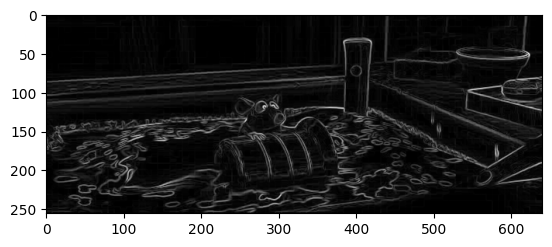

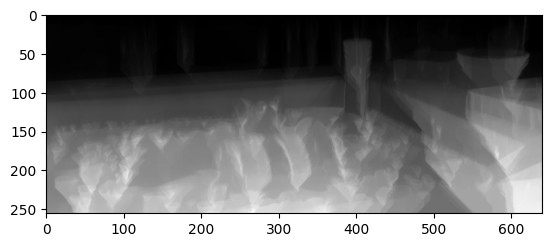

In [6]:
back_energy = backward_energy(frames[0], visualize=True)
for_energy = forward_energy(frames[0], visualize=True)

In [7]:
def get_static_energy(frames):
    forward_energy_maps = []

    for frame in frames:
        for_energy = forward_energy(frame)
        forward_energy_maps.append(for_energy)
    
    back_energy_stack = np.stack(forward_energy_maps, axis=0)
    static_energy = np.max(back_energy_stack, axis=0)    # Max
    # static_energy = back_energy_stack.mean(axis=0)    # Mean
    # static_energy = np.median(back_energy_stack, axis=0)    # Median

    return static_energy

In [8]:
def get_temporal_energy(frames):
    temp_energy = np.zeros((frames[0].shape[0], frames[0].shape[1]), dtype=np.float32)
    
    for t in range(1, len(frames)):
        diff = np.abs(frames[t].astype(np.float32) - frames[t-1].astype(np.float32))
        temp_energy = np.maximum(temp_energy, diff.sum(axis=2))  

    return temp_energy

In [9]:
def find_vertical_seam(energy_map):
    energy = energy_map.copy()
    backtrack = np.zeros(energy.shape, dtype=np.int32)

    for i in range(1, energy.shape[0]):
        left = energy[i-1, :-2]
        middle = energy[i-1, 1:-1]
        right = energy[i-1, 2:]

        left = np.pad(left, (1,1), constant_values=np.inf)
        middle = np.pad(middle, (1,1), constant_values=np.inf)
        right = np.pad(right, (1,1), constant_values=np.inf)

        prev = np.vstack([left, middle, right])   
        choices = np.argmin(prev, axis=0)
        backtrack[i] = np.arange(energy.shape[1]) + (choices - 1)

        energy[i] += prev[choices, np.arange(energy.shape[1])]
        
    seam = np.zeros(energy.shape[0], dtype=np.int32)
    seam[-1] = np.argmin(energy[-1])

    for i in range(energy.shape[0]-2, -1, -1):
        seam[i] = backtrack[i+1, seam[i+1]]

    return seam

# Horizontal seam for A is nothing but vertical seam for A
def find_horizontal_seam(energy):
    return find_vertical_seam(energy.T)

In [10]:
def remove_vertical_seam(frames, seam):
    out_frames = []
    h, w, c = frames[0].shape
    for frame in frames:
        out = np.zeros((h, w-1, c), dtype=frame.dtype)
        for i in range(h):
            j = seam[i]
            out[i, :, :] = np.delete(frame[i, :, :], j, axis=0)
        out_frames.append(out)
    return out_frames

def remove_horizontal_seam(frames, seam):
    out_frames = []
    h, w, c = frames[0].shape
    for frame in frames:
        out = np.zeros((h-1, w, c), dtype=frame.dtype)
        for j in range(w):
            i = seam[j]
            out[:, j, :] = np.delete(frame[:, j, :], i, axis=0)
        out_frames.append(out)
    return out_frames

In [11]:
def resize(frames, target_h, target_w, alpha=0.5):
    modified_frames = frames.copy()
    num_vertical_seams = frames[0].shape[1] - target_w
    num_horizontal_seams = frames[0].shape[0] - target_h

    while (num_vertical_seams > 0) or (num_horizontal_seams > 0):
        static_energy = get_static_energy(modified_frames)
        temporal_energy = get_temporal_energy(modified_frames)

        energy = alpha*static_energy + (1 - alpha)*(temporal_energy)

        if (num_horizontal_seams == 0):
            seam = find_vertical_seam(energy)
            modified_frames = remove_vertical_seam(modified_frames, seam)
            num_vertical_seams -= 1

        elif (num_vertical_seams == 0):
            seam = find_vertical_seam(energy.T)    # Horizontal seam for A is nothing but vertical seam for A.
            modified_frames = remove_horizontal_seam(modified_frames, seam)
            num_horizontal_seams -= 1
        
        else:
            vertical_seam = find_vertical_seam(energy)
            vertical_cost = energy[np.arange(len(vertical_seam)), vertical_seam].sum()
            horizontal_seam = find_vertical_seam(energy.T)
            horizontal_cost = energy.T[np.arange(len(horizontal_seam)), horizontal_seam].sum()

            if (vertical_cost <= horizontal_cost):
                seam = find_vertical_seam(energy)
                modified_frames = remove_vertical_seam(modified_frames, seam)
                num_vertical_seams -= 1
            else:
                seam = find_vertical_seam(energy.T)    # Horizontal seam for A is nothing but vertical seam for A.
                modified_frames = remove_horizontal_seam(modified_frames, seam)
                num_horizontal_seams -= 1
        
    return modified_frames   

5 (256, 640, 3)


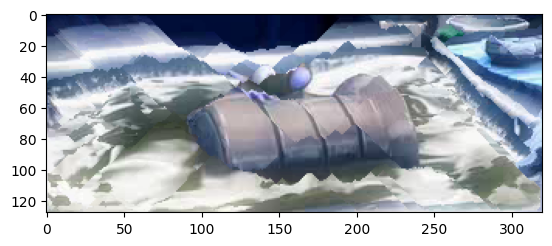

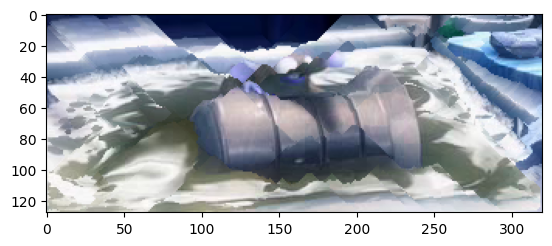

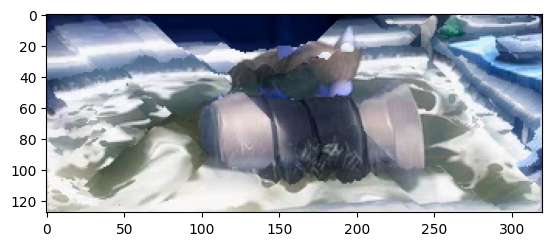

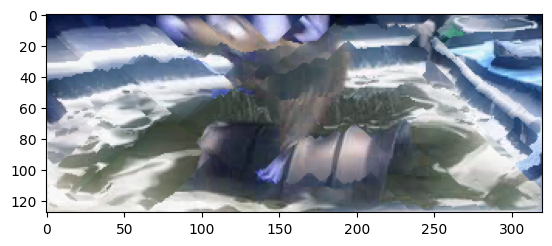

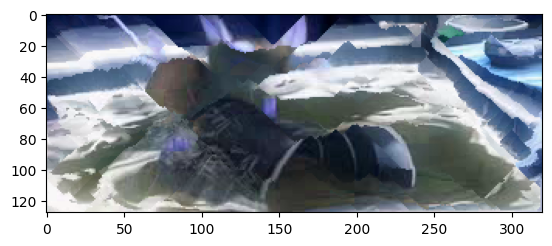

In [14]:
# Testing on one image
test_frames = frames[:60:12]    # Choosing 5 frames from video
print(len(test_frames), test_frames[0].shape)

# alpha = 0 means we preserve only moving objects, while alpha = 1 means we preserve energies in a frame
modified_frames = resize(test_frames, 128, 320, alpha=0)    
# modified_frames = resize(test_frames, 200, 200, alpha=1)

for modified_img in modified_frames:
    plt.imshow(modified_img)
    plt.show()

# Note: The effect is particularly visible in the second frame of this output, where the golf stick is different for both cases of alpha. 
# When alpha is 0, the golf stik is retained as it is. 
# However, when alpha is 1, we can see distorted and broken golf stick.

In [15]:
# Running static seam carving for all frames
target_h = 128   # 200
target_w = 320    # 200
modified_frames = resize(frames, target_h, target_w)

In [16]:
def save_video(frames, output_path, fps=30):
    h, w, c = frames[0].shape
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    writer = cv2.VideoWriter(output_path, fourcc, fps, (w, h), isColor=True)

    for f in frames:
        writer.write(f)
    writer.release()
    
    print(f"Saved output video to {output_path}")

In [ ]:
save_video(modified_frames, "../assets/output/seam_carving/static_approach/static_seam_carving_output_ratatouille1.mp4", fps=30)

Saved output video to ../assets/output/static_seam_carving_output_ratatouille1.mp4
